# Session 4 lab: What does a typical order look like?

<p class="lead">
Describe order values, delivery times and profits with the right statistics and charts, find the long tails, and flag unusual records without throwing them away.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/04_descriptive_statistics_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The operations and finance leads ask:

> *"Our monthly report says the average order is worth a lot and delivery takes a few days. Is that what a typical customer experiences? What should we promise customers about delivery, and which orders need a closer look?"*

Before anyone sets a promise or a target, you describe the distributions properly.

> **About the data**
>
> **Superstore** is a sample published by Tableau about a **fictitious** company. Sales and Profit are in **source monetary units**; the file does not state a currency.
>
> **US house prices** come from the **U.S. Census Bureau**'s New Residential Sales survey, as mirrored in Tableau's sample-data catalog. Prices are in US dollars of each month (not adjusted for inflation).

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I6 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Build an order-level table from order lines and check the grain.
2. Describe a variable with centre, spread, percentiles and skew, and choose which to report.
3. Draw and read histograms, box plots and an ECDF, and compare groups.
4. Flag unusual values with the IQR rule without deleting them.
5. Explain a mean–median gap on real public data.

**Evidence you keep:** a distribution summary table with your reporting choices, two charts with one-sentence readings, and your corrected "average order value" statement.

---

## Guided practice

### G1 (Core): Load the data and build an order-level table

Run the setup cell first.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
import numpy as np

df = load_orders()
print("Order lines:", len(df))

Order lines: 6815


The questions today are about **orders**, so we build a table with one row per order. The check underneath proves that segment, ship mode and ship days never vary inside an order.

In [3]:
# One row per ORDER: add up the lines of each order.
# Segment, ship mode and ship days are the same on every line of an order, so we take the first.
orders = df.groupby("order_id").agg(
    order_value=("sales", "sum"),
    segment=("segment", "first"),
    ship_mode=("ship_mode", "first"),
    ship_days=("order_to_ship_days", "first"),
)

# Check that claim before relying on it: each should be 1.
per_order = df.groupby("order_id")[["segment", "ship_mode", "order_to_ship_days"]].nunique()
print("Most different values inside one order:")
print(per_order.max())
print("Orders:", len(orders))

Most different values inside one order:
segment               1
ship_mode             1
order_to_ship_days    1
dtype: int64
Orders: 3388


In [4]:
orders.head()

,order_value,segment,ship_mode,ship_days
order_id,,,,
CA-2023-100867,32.70,Home Office,Standard Class,5
CA-2023-107153,10.69,Corporate,Standard Class,5
CA-2023-115238,281.16,Corporate,Standard Class,3
CA-2023-115777,387.99,Consumer,Standard Class,5
CA-2023-117964,56.42,Corporate,Standard Class,4


> **Write your grain statement**
>
> Complete in your evidence log: *"In `orders`, one row is one ______. `order_value` is the sum of ______ for all lines in the order."*

### G2 (Core): Describe order value

`describe()` gives the count, mean, standard deviation, minimum, quartiles and maximum in one go. We add the median, more percentiles and the skew.

In [5]:
ov = orders["order_value"]
print(ov.describe())
print()
print("Median:", round(ov.median(), 2))
print("Skew:  ", round(ov.skew(), 2))

count    3,388.00
mean       466.64
std        975.36
min          0.84
25%         38.33
50%        151.46
75%        531.66
max     23,661.23
Name: order_value, dtype: float64

Median: 151.46
Skew:   8.86


In [6]:
ov.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame("order value")

,order value
0.10,12.96
0.25,38.33
0.50,151.46
0.75,531.66
0.90,"1,181.29"
0.95,"1,789.85"
0.99,"4,256.06"


Compare the mean with the median in the output above, and look at how far apart the 90th and 99th percentiles are.

> **Write it down**
>
> In one sentence: is order value symmetric or skewed, and which side is the long tail on? Quote the two numbers that prove it.

### G3 (Core): Picture order value

Three views of the same column. The log-binned histogram spreads small and large orders out; the box plot shows the middle half and the flagged values; the ECDF lets you read any percentile.

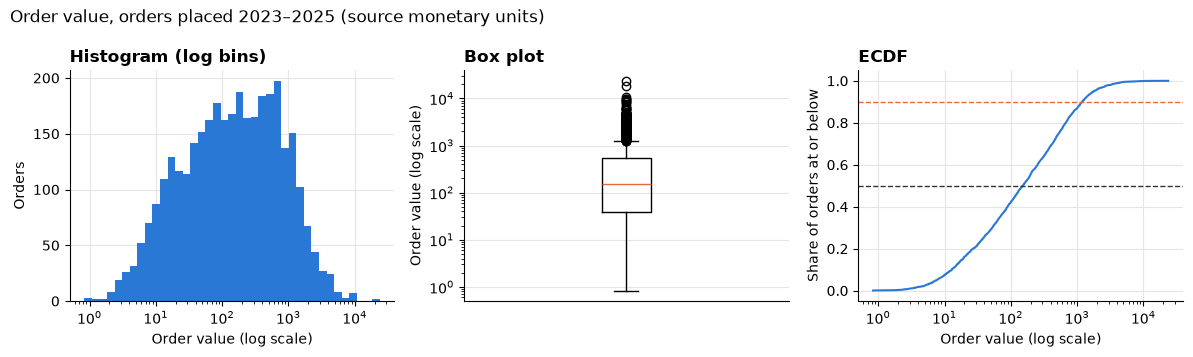

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

log_bins = np.logspace(np.log10(ov.min()), np.log10(ov.max()), 40)
axes[0].hist(ov, bins=log_bins)
axes[0].set_xscale("log")
axes[0].set_title("Histogram (log bins)")
axes[0].set_xlabel("Order value (log scale)")
axes[0].set_ylabel("Orders")

axes[1].boxplot(ov)
axes[1].set_yscale("log")
axes[1].set_title("Box plot")
axes[1].set_ylabel("Order value (log scale)")
axes[1].set_xticks([])

axes[2].plot(np.sort(ov), np.arange(1, len(ov) + 1) / len(ov))
axes[2].set_xscale("log")
axes[2].axhline(0.5, color="#333333", linestyle="--", linewidth=1)
axes[2].axhline(0.9, color="#eb6834", linestyle="--", linewidth=1)
axes[2].set_title("ECDF")
axes[2].set_xlabel("Order value (log scale)")
axes[2].set_ylabel("Share of orders at or below")

fig.suptitle("Order value, orders placed 2023–2025 (source monetary units)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

On the ECDF, the dashed lines at 0.5 and 0.9 cross the curve at the median and the 90th percentile. Check that they match the percentile table in G2.

### G4 (Core): Ship days

Ship days are whole numbers with few possible values, so one bar per value is clearer than a histogram.

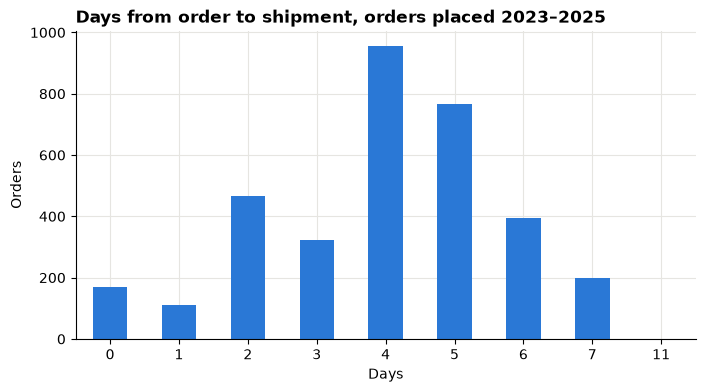

Mean: 3.97 | median: 4.0 | mode: 4 | skew: -0.42
90th percentile: 6.0 | 95th percentile: 7.0


In [8]:
sd = orders["ship_days"]
sd.value_counts().sort_index().plot(kind="bar", title="Days from order to shipment, orders placed 2023–2025")
plt.xlabel("Days")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.show()

print("Mean:", round(sd.mean(), 2), "| median:", sd.median(), "| mode:", sd.mode()[0], "| skew:", round(sd.skew(), 2))
print("90th percentile:", sd.quantile(0.9), "| 95th percentile:", sd.quantile(0.95))

Is there a value far from all the others at the right end? Look at those orders:

In [9]:
gap_limit = sd.quantile(0.99)
orders[orders["ship_days"] > gap_limit]

,order_value,segment,ship_mode,ship_days
order_id,,,,
CA-2023-153623,198.24,Corporate,Standard Class,11


These orders are possible but unusual. We **keep** them and note them for the operations team; we do not delete them.

### G5 (Core): Compare groups

A single summary hides differences between groups. Here is order value by segment: the median and IQR next to the mean, then box plots side by side.

In [10]:
def robust_summary(data, value, by):
    g = data.groupby(by)[value]
    table = pd.DataFrame({
        "orders": g.count(),
        "mean": g.mean(),
        "median": g.median(),
        "q1": g.quantile(0.25),
        "q3": g.quantile(0.75),
    })
    table["IQR"] = table["q3"] - table["q1"]
    return table

robust_summary(orders, "order_value", "segment")

,orders,mean,median,q1,q3,IQR
segment,,,,,,
Consumer,1738,480.87,164.99,39.19,555.64,516.45
Corporate,1044,447.86,148.67,40.79,523.18,482.39
Home Office,606,458.18,122.00,31.92,466.81,434.89


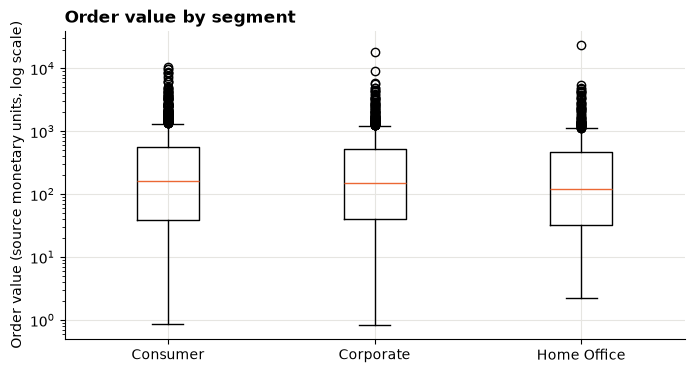

In [11]:
groups = sorted(orders["segment"].unique())
plt.boxplot([orders.loc[orders["segment"] == g, "order_value"] for g in groups])
plt.xticks(range(1, len(groups) + 1), groups)
plt.yscale("log")
plt.title("Order value by segment")
plt.ylabel("Order value (source monetary units, log scale)")
plt.show()

> **Read the chart**
>
> Do the boxes overlap a lot or a little? Does the segment with the highest mean also have the highest median? Write one sentence in your log.

---

## Independent tasks

### I1 (Core): Your own group comparison

Use the same two tools for a new question: how do **ship days** differ by **ship mode**?

> **Your turn:** change the code in the next cell and run it again.

,orders,mean,median,q1,q3,IQR
ship_mode,,,,,,
First Class,508,2.19,2.00,2.00,3.00,1.00
Same Day,176,0.04,0.00,0.00,0.00,0.00
Second Class,652,3.23,3.00,2.00,4.00,2.00
Standard Class,2052,4.99,5.00,4.00,6.00,2.00


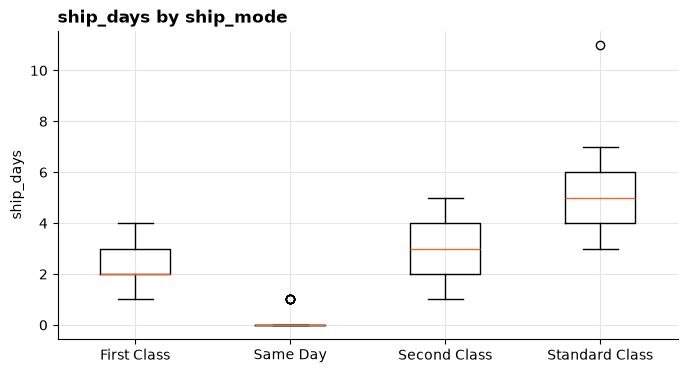

In [12]:
# 1. Run as it is: ship days by ship mode.
# 2. Then change value to "order_value" and by to "ship_mode", or value to "ship_days" and by to "segment".
# 3. For each, write one sentence: which group differs most, and is it the centre or the spread?
value = "ship_days"
by = "ship_mode"

display(robust_summary(orders, value, by))

groups = sorted(orders[by].unique())
plt.boxplot([orders.loc[orders[by] == g, value] for g in groups])
plt.xticks(range(1, len(groups) + 1), groups)
plt.title(f"{value} by {by}")
plt.ylabel(value)
plt.show()

### I2 (Core): The long tail of profit

Profit can be negative: a line can lose money, for example after a large discount. This task works at the **order-line** grain, because discounts are set per line.

count    6,815.00
mean        28.81
std        228.33
min     -6,599.98
25%          1.74
50%          8.82
75%         29.95
max      8,399.98
Name: profit, dtype: float64

Share of lines with negative profit: 18.6%
Median: 8.82 | skew: 7.24


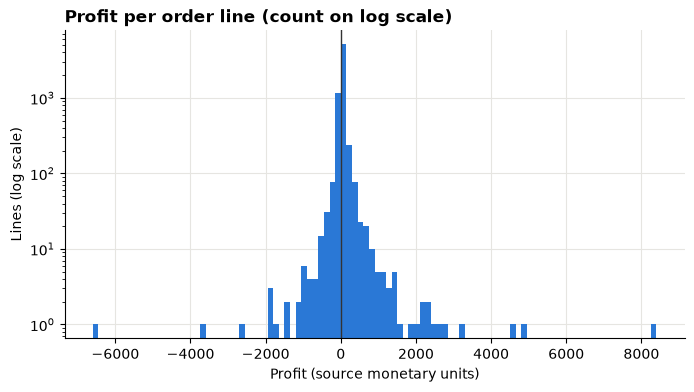

In [13]:
profit = df["profit"]
print(profit.describe())
print()
print("Share of lines with negative profit:", f"{(profit < 0).mean():.1%}")
print("Median:", round(profit.median(), 2), "| skew:", round(profit.skew(), 2))

plt.hist(profit, bins=100)
plt.axvline(0, color="#333333", linewidth=1)
plt.yscale("log")
plt.title("Profit per order line (count on log scale)")
plt.xlabel("Profit (source monetary units)")
plt.ylabel("Lines (log scale)")
plt.show()

The vertical axis is on a log scale so that the rare, extreme lines are visible at all. Profit has tails on **both** sides.

Now look at the ten lines that lost the most:

> **Your turn:** change the code in the next cell and run it again.

In [14]:
# 1. Run it: the ten most negative lines with their discount.
# 2. Change nsmallest to nlargest to see the most profitable lines. What do their discounts look like?
# 3. Write one sentence on what the losing lines have in common.
df.nsmallest(10, "profit")[["order_id", "category", "sub_category", "sales", "discount", "profit"]]

,order_id,category,sub_category,sales,discount,profit
6398,US-2025-108196,Technology,Machines,"4,499.99",0.70,"-6,599.98"
821,US-2023-169019,Office Supplies,Binders,"2,177.58",0.80,"-3,701.89"
4037,US-2024-147830,Technology,Machines,"1,799.99",0.70,"-2,639.99"
2108,US-2024-116638,Furniture,Tables,"4,297.64",0.40,"-1,862.31"
4570,US-2025-130946,Office Supplies,Binders,"1,088.79",0.80,"-1,850.95"
226,US-2023-145317,Technology,Machines,"22,638.48",0.50,"-1,811.08"
3203,US-2024-150630,Furniture,Bookcases,"3,083.43",0.50,"-1,665.05"
1549,US-2023-165309,Office Supplies,Binders,896.99,0.80,"-1,480.03"
1063,US-2023-139892,Technology,Machines,"8,159.95",0.40,"-1,359.99"
2354,US-2024-140025,Office Supplies,Appliances,463.25,0.80,"-1,181.28"


> **Think about it**
>
> Would the mean profit per line be a fair "typical profit" for a manager? What would you report instead, and what would you add so the losses are not hidden?

### I3 (Core): US house prices — mean versus median

The Census Bureau reports both the **median** and the **average** (mean) sales price of new single-family houses sold in the United States. Comparing them shows the shape of house prices without seeing a single individual sale.

Run the cell to download the file and check its fingerprint.

In [15]:
# U.S. Census Bureau, New Residential Sales, as mirrored in Tableau's sample-data catalog.
# The file is read straight into memory; nothing is saved to disk.
import hashlib
import io
import urllib.request

HOME_URL = ("https://public.tableau.com/app/sample-data/"
            "enigma-us.gov_.census.eits_.ressales-e7513e56d76050c05caf638306055c98_1.csv")
HOME_SHA256 = "cc5df3053fdf6b4b732ed5a3cc10f1e389f7c7ca70b2048a53fd16454dca0be6"

home_bytes = urllib.request.urlopen(HOME_URL).read()
if hashlib.sha256(home_bytes).hexdigest() != HOME_SHA256:
    print("WARNING: this file has changed since the course was written. Tell your facilitator.")
home_raw = pd.read_csv(io.BytesIO(home_bytes))
print("Rows, columns:", home_raw.shape)
home_raw.head(3)

Rows, columns: (20404, 20)


,per_idx,per_name,cat_idx,cat_code,cat_desc,cat_indent,dt_idx,dt_code,dt_desc,dt_unit,et_idx,et_code,et_desc,et_unit,geo_idx,geo_code,geo_desc,is_adj,val,serialid
0,1,1963-01-01,1,SOLD,New Single-family Houses Sold,0,5,MEDIAN,Median Sales Price,DOL,0,NaN,NaN,NaN,1,US,United States,0,"17,200.00",1
1,1,1963-01-01,1,SOLD,New Single-family Houses Sold,0,2,NOTSTD,Houses that are Not Started,K,0,NaN,NaN,NaN,1,US,United States,0,9.00,2
2,1,1963-01-01,1,SOLD,New Single-family Houses Sold,0,3,UNDERC,Houses that are Under Construction,K,0,NaN,NaN,NaN,1,US,United States,0,11.00,3


The file is in **long format**: many measures stacked in one `val` column. We need to choose **one consistent series**. The codes:

| Column | Value we keep | Meaning |
|---|---|---|
| `cat_code` | `SOLD` | New single-family houses **sold** (not for sale) |
| `geo_code` | `US` | The whole United States, not one region |
| `is_adj` | `0` | Not seasonally adjusted (prices are only published this way) |
| `dt_code` | `MEDIAN` and `AVERAG` | Median and average sales price, in dollars |

Mixing categories, regions or adjustments would produce a meaningless series, so every filter is written down.

In [16]:
selection = (
    (home_raw["cat_code"] == "SOLD")
    & (home_raw["geo_code"] == "US")
    & (home_raw["is_adj"] == 0)
    & (home_raw["dt_code"].isin(["MEDIAN", "AVERAG"]))
)
prices = home_raw.loc[selection, ["per_name", "dt_code", "val"]]
print("Units:", home_raw.loc[selection, "dt_unit"].unique())
print("Any month listed twice?", prices.duplicated(["per_name", "dt_code"]).any())

# One row per month, one column per measure; keep months that have both.
prices = prices.pivot(index="per_name", columns="dt_code", values="val").dropna()
prices.index = pd.to_datetime(prices.index)
prices = prices.rename(columns={"MEDIAN": "median_price", "AVERAG": "average_price"})
print("Months:", len(prices), "from", prices.index.min().date(), "to", prices.index.max().date())
prices.head()

Units: ['DOL']
Any month listed twice? False
Months: 502 from 1975-01-01 to 2016-10-01


dt_code,average_price,median_price
per_name,,
1975-01-01,"39,500.00","37,200.00"
1975-02-01,"40,600.00","37,900.00"
1975-03-01,"42,100.00","38,800.00"
1975-04-01,"42,000.00","39,200.00"
1975-05-01,"43,200.00","39,500.00"


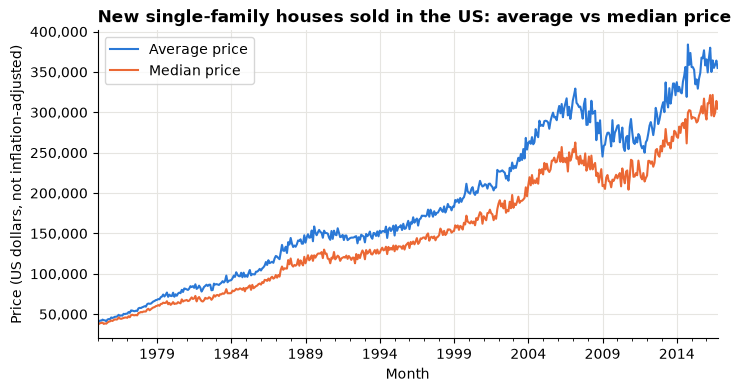

Months where the average is above the median: 100%
count   502.00
mean      1.20
std       0.05
min       1.06
25%       1.18
50%       1.20
75%       1.23
max       1.34
Name: ratio, dtype: float64


In [17]:
prices[["average_price", "median_price"]].plot(
    title="New single-family houses sold in the US: average vs median price")
plt.legend(["Average price", "Median price"])
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.ylabel("Price (US dollars, not inflation-adjusted)")
plt.xlabel("Month")
plt.show()

prices["ratio"] = prices["average_price"] / prices["median_price"]
print("Months where the average is above the median:", f"{(prices['ratio'] > 1).mean():.0%}")
print(prices["ratio"].describe())

> **Explain it**
>
> In two sentences: what does the average sitting above the median every month tell you about the distribution of individual house prices? Which number should a news report use for "a typical new house"?

> **Your turn:** change the code in the next cell and run it again.

In [18]:
# Compare the gap in two periods.
# 1. Run it as it is.
# 2. Change the years to compare other decades, e.g. "1990"–"1999" and "2010"–"2016".
# 3. Has the gap between average and median grown or shrunk? What could explain that?
early = prices.loc["1975":"1984", "ratio"].mean()
late = prices.loc["2007":"2016", "ratio"].mean()
print("Average / median, first period: ", round(early, 3))
print("Average / median, second period:", round(late, 3))

Average / median, first period:  1.156
Average / median, second period: 1.214


Credit for your log: *"Source: U.S. Census Bureau, New Residential Sales; mirrored in Tableau's sample-data catalog; series: houses sold, United States, not seasonally adjusted, median and average sales price."*

### I4 (Core): Flag unusual orders with the IQR rule

Add a **flag** column; do not delete anything.

In [19]:
q1, q3 = ov.quantile(0.25), ov.quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
lower_fence = q1 - 1.5 * (q3 - q1)
print("Lower fence:", round(lower_fence, 2), "| upper fence:", round(upper_fence, 2))

orders["high_value_flag"] = (orders["order_value"] > upper_fence).astype(int)
flagged = orders[orders["high_value_flag"] == 1]
print("Orders flagged:", len(flagged), f"({len(flagged) / len(orders):.1%} of orders)")
print("Their share of total sales:", f"{flagged['order_value'].sum() / ov.sum():.1%}")

Lower fence: -701.67 | upper fence: 1271.66
Orders flagged: 305 (9.0% of orders)
Their share of total sales: 50.0%


Read the two percentages. Would deleting these orders "clean" the data, or remove a large part of the business?

> **Your turn:** change the code in the next cell and run it again.

In [20]:
# Apply the same rule to another column.
# 1. Change "order_value" to "ship_days". How many orders are flagged, and on which side?
# 2. Then try line-level profit: set table = df and column = "profit". Count low AND high flags.
table = orders
column = "order_value"

s = table[column]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print("Fences:", round(low, 2), "to", round(high, 2))
print("Flagged low: ", (s < low).sum())
print("Flagged high:", (s > high).sum())

Fences: -701.67 to 1271.66
Flagged low:  0
Flagged high: 305


### I5 (Core): Your distribution summary table

This is the evidence for today. The function computes the statistics; **you** fill in the reporting choice.

In [21]:
def describe_shape(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "IQR": q3 - q1,
        "90th pct": s.quantile(0.9),
        "skew": s.skew(),
    })

summary = pd.DataFrame({
    "order value (per order)": describe_shape(orders["order_value"]),
    "ship days (per order)": describe_shape(orders["ship_days"]),
    "profit (per line)": describe_shape(df["profit"]),
}).T
summary

,count,mean,median,std,IQR,90th pct,skew
order value (per order),"3,388.00",466.64,151.46,975.36,493.33,"1,181.29",8.86
ship days (per order),"3,388.00",3.97,4.00,1.73,2.00,6.00,-0.42
profit (per line),"6,815.00",28.81,8.82,228.33,28.21,89.95,7.24


> **Your turn:** change the code in the next cell and run it again.

In [22]:
# Fill in your reporting choice for each variable, then run the cell.
# Use the shape (mean vs median, skew) to decide.
summary["centre to report"] = ["write here", "write here", "write here"]
summary["spread to report"] = ["write here", "write here", "write here"]
summary[["mean", "median", "skew", "centre to report", "spread to report"]]

,mean,median,skew,centre to report,spread to report
order value (per order),466.64,151.46,8.86,write here,write here
ship days (per order),3.97,4.00,-0.42,write here,write here
profit (per line),28.81,8.82,7.24,write here,write here


### I6 (Stretch): How normal is it?

Compare the share of values within 1, 2 and 3 standard deviations with the normal reference (68%, 95%, 99.7%).

> **Your turn:** change the code in the next cell and run it again.

In [23]:
# 1. Run it for order value.
# 2. Change the column to orders["ship_days"], then to df["profit"].
# 3. Which variable is closest to the normal reference? Which is furthest, and why?
s = orders["order_value"]
z = (s - s.mean()) / s.std()
for k, reference in [(1, 68.3), (2, 95.4), (3, 99.7)]:
    print(f"within {k} sd: {(z.abs() <= k).mean():.1%}  (normal reference {reference}%)")
print("Largest z-score:", round(z.max(), 1))

within 1 sd: 92.8%  (normal reference 68.3%)
within 2 sd: 96.9%  (normal reference 95.4%)
within 3 sd: 98.4%  (normal reference 99.7%)
Largest z-score: 23.8


---

## Challenge

### C1 (Challenge): Debug a colleague's "average order value"

A colleague writes in the monthly report:

> *"Our average order value is* `df["sales"].mean()` *, so a typical customer order is worth about that much."*

> **Your turn:** change the code in the next cell and run it again.

In [24]:
# The colleague's code. It runs, but the sentence is wrong in two ways.
# 1. Find both mistakes (one is about the grain, one is about the shape).
# 2. Fix the code so it answers "what is a typical order worth?"
# 3. Rewrite the colleague's sentence so it is correct.
colleague_aov = df["sales"].mean()
print("Colleague's 'average order value':", round(colleague_aov, 2))

Colleague's 'average order value': 231.98


> **How would you check your fix?**
>
> Your corrected mean order value multiplied by the number of orders must equal total sales. Your "typical order" number should match the median in G2.

### C2 (Challenge): Set a delivery promise

The operations lead wants one sentence per ship mode: *"We ship within N days for P% of orders."*

> **Your turn:** change the code in the next cell and run it again.

In [25]:
# 1. Run it with share = 0.90.
# 2. Try 0.95 and 0.99. How does the promise change, and for which ship mode is it least stable?
# 3. Write one promise sentence per ship mode. Which share would you recommend, and why not 100%?
share = 0.90
promise = orders.groupby("ship_mode")["ship_days"].quantile(share)
achieved = {m: (orders.loc[orders["ship_mode"] == m, "ship_days"] <= promise[m]).mean() for m in promise.index}
pd.DataFrame({"promise (days)": promise, "share actually within": pd.Series(achieved)})

,promise (days),share actually within
First Class,3.00,1.00
Same Day,0.00,0.96
Second Class,5.00,1.00
Standard Class,6.00,0.90


Why can "share actually within" be higher than the share you chose? (Hint: ship days are whole numbers, and many orders share the same value.)

---

## Exit ticket

1. One sentence: what is the typical order value, and why is it not the mean?
2. One sentence: what share of order lines lose money?
3. One question you would ask the operations team about the longest ship times.

---

## Evidence to keep

- [ ] Grain statement for the `orders` table (G1)
- [ ] Order value description with mean, median and skew (G2)
- [ ] One group comparison with a one-sentence reading (G5 or I1)
- [ ] House-price mean–median explanation with the source credit (I3)
- [ ] IQR flag counts and the share of sales they represent (I4)
- [ ] Distribution summary table with your reporting choices (I5)
- [ ] Corrected "average order value" sentence (C1, if attempted)

---

## After the lab

Next: Session 5, **Metrics and KPIs**, where averages become ratios of totals. Its draft lab is [Which segment deserves a closer look?](05_metrics_and_kpis_lab.md).